# Alex — Hotel Booking EDA
**CS611 | Formal data preparation review | T−14 | H1 Resort / H2 City**

This notebook independently checks the source data and translates findings into proposed preparation rules. Helen's original notebook is kept unchanged beside this file. It does not train models or write Bronze/Silver/Gold tables.

## Summary
Start with the [final measured summary](#Final-measured-summary), then inspect the relevant sections and saved tables.

In [1]:
from pathlib import Path
import calendar, hashlib, json, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Locate the project from either its root or its EDA directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/H1.csv').exists())
OUT = ROOT / 'EDA/results'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
X = 14
PEOPLE_PER_ROOM = {'H1': 2, 'H2': 4}
COLORS = {'H1': '#2563A6', 'H2': '#CF6F32'}
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.grid': False})
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 35)

def save_table(table, name):
    table.to_csv(OUT / (name + '.csv'), index=False)
    return table

def show_figure(name):
    plt.tight_layout()
    plt.savefig(FIG / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

versions = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__}
print('Runtime:', versions)
print('Prediction cutoff: end of T-14 day. Rooms: H1 / 2; H2 / 4.')

Runtime: {'python': '3.12.14', 'pandas': '2.2.3', 'numpy': '2.2.2'}
Prediction cutoff: end of T-14 day. Rooms: H1 / 2; H2 / 4.


## Context and methods

- **Population:** original paper H1 (40,060 rows) and H2 (79,330 rows), with 31 source columns each. Dates span July 2015–August 2017.
- **Grain:** one source row per booking; identical-looking rows are retained. A generated ID identifies a source row, not a real customer.
- **T−14:** retain `LeadTime >= 14`; exclude `Canceled` / `No-Show` with `ReservationStatusDate <= ArrivalDate − 14 days`. Use existing `IsCanceled`.
- **Boundary:** dates have no time of day. Include bookings created on the cutoff date and exclude outcomes recorded on that date: an end-of-day convention.

### Key assumptions
- The team treats retained booking details as unchanged before scoring for this offline prototype.
- Room capacity is a scenario assumption: **H1 = 2 people; H2 = 4 people**. Main room estimates use `Adults + Children + Babies`, preserving missing totals; an adults-only sensitivity is also shown because Helen's notebook used adults only.
- EDA uses all historical rows for inspection. Feature selection, learned imputation, encoding, scaling and model comparison must use training/validation data, not the held-out test set.
- Current downloads can contain later statistical revisions. Download time is not the historical publication date.

### Sources
- [Original hotel dataset and Table 1](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/).
- [Author's deployment study: Country leakage and H2 soft opening](https://datascience.codata.org/articles/10.5334/dsj-2019-032).
- Holiday API responses checked against [Law 23/2012](https://diariodarepublica.pt/dr/detalhe/lei/23-2012-178501) and [Law 8/2016](https://diariodarepublica.pt/dr/detalhe/lei/8-2016-74007209).
- [ECB EUR/USD](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/eurofxref-graph-usd.en.html).

Exact download URLs, retrieval timestamps and SHA-256 checksums are in `data/external/source_manifest.json` and the per-file metadata.

## 1. Verify and load the original hotel data
Original files are never modified. Whitespace is stripped in memory; `NULL` in Agent/Company is tracked separately from missing measurements.

In [2]:
EXPECTED = {'H1': '6f38fda13794fd6cf6547d2432ffb79666200000eb45fd09e4b97fe49519a6ab',
            'H2': '5107090ffdc5585a9e18299801e9d85c3b459c235542882183a502a73ef63c4d'}
TEXT = ['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel',
        'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company',
        'CustomerType', 'ReservationStatus', 'ReservationStatusDate']
raw, frames, profiles, hashes = {}, [], [], []
month_map = {name: i for i, name in enumerate(calendar.month_name) if name}
for hotel in ['H1', 'H2']:
    path = ROOT / f'data/raw/{hotel}.csv'
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == EXPECTED[hotel], f'Source changed: {hotel}'
    source = pd.read_csv(path, dtype=str, keep_default_na=False)
    source.columns = source.columns.str.strip()
    assert source.shape == ({'H1': 40060, 'H2': 79330}[hotel], 31)
    trimmed = source.apply(lambda s: s.str.strip())
    raw[hotel] = trimmed
    profiles.append({'Hotel': hotel, 'Rows': len(source), 'Source columns': len(source.columns),
        'Cells with whitespace': int(sum((source[c] != trimmed[c]).sum() for c in source)),
        'Extra identical rows': int(trimmed.duplicated().sum()),
        'Rows in duplicate groups': int(trimmed.duplicated(keep=False).sum())})
    d = trimmed.copy()
    for column in [c for c in d if c not in TEXT]:
        d[column] = pd.to_numeric(d[column].replace({'NULL': np.nan, 'NA': np.nan, '': np.nan}), errors='raise')
    d['Hotel'] = hotel
    d['Booking_ID'] = [f'{hotel}-{i:06d}' for i in range(1, len(d) + 1)]
    d['ArrivalDate'] = pd.to_datetime(dict(year=d.ArrivalDateYear,
        month=d.ArrivalDateMonth.map(month_map), day=d.ArrivalDateDayOfMonth), errors='raise')
    d['ReservationStatusDate'] = pd.to_datetime(d.ReservationStatusDate, errors='raise')
    d['BookingCreatedDate'] = d.ArrivalDate - pd.to_timedelta(d.LeadTime, unit='D')
    d['CutoffDate'] = d.ArrivalDate - pd.Timedelta(days=X)
    d['TotalNights'] = d[['StaysInWeekNights', 'StaysInWeekendNights']].sum(axis=1, min_count=2)
    d['PartySize'] = d[['Adults', 'Children', 'Babies']].sum(axis=1, min_count=3)
    frames.append(d)
    hashes.append({'file': f'data/raw/{hotel}.csv', 'sha256': sha})
df = pd.concat(frames, ignore_index=True)
assert df.Booking_ID.is_unique
profile = save_table(pd.DataFrame(profiles), 'source_profile')
display(profile)
display(df.groupby('Hotel').agg(First_arrival=('ArrivalDate', 'min'), Last_arrival=('ArrivalDate', 'max')))
(OUT / 'input_hashes.json').write_text(json.dumps(hashes, indent=2), encoding='utf-8')

,Hotel,Rows,Source columns,Cells with whitespace,Extra identical rows,Rows in duplicate groups
0,H1,40060,31,279251,6092,8417
1,H2,79330,31,555310,25902,31748


,First_arrival,Last_arrival
Hotel,,
H1,2015-07-01,2017-08-31
H2,2015-07-01,2017-08-31


244

**Interpretation:** duplicate-group counts include every member, while extra-identical counts exclude the first copy. Both are valid measures with different meanings. Keep the source rows; deduplicating all 31 columns could remove separate bookings. Source-row IDs remain stable only while the original file and row order are preserved.

## 2. Missingness, categories and numeric quality

In [3]:
missing_rows, categories = [], []
for hotel, d in raw.items():
    for column in d:
        n = int(d[column].isin(['', 'NULL', 'NA']).sum())
        if n:
            missing_rows.append({'Hotel': hotel, 'Column': column, 'Rows': n,
                'Percent': round(100 * n / len(d), 3),
                'Meaning': 'No agent/company recorded' if column in ['Agent','Company'] else 'Missing value'})
    for column in [c for c in TEXT if c not in ['ReservationStatusDate']]:
        values = sorted(d[column].unique())
        categories.append({'Hotel': hotel, 'Column': column, 'Distinct values': len(values),
                           'Values / examples': ', '.join(values) if len(values) <= 15 else ', '.join(values[:12]) + ' ...'})
missing = save_table(pd.DataFrame(missing_rows), 'missingness')
display(missing)
category_table = save_table(pd.DataFrame(categories), 'category_inventory')
display(category_table[~category_table.Column.isin(['Country','Agent','Company'])])

,Hotel,Column,Rows,Percent,Meaning
0,H1,Country,464,1.158,Missing value
1,H1,Agent,8209,20.492,No agent/company recorded
2,H1,Company,36952,92.242,No agent/company recorded
3,H2,Children,4,0.005,Missing value
4,H2,Country,24,0.030,Missing value
5,H2,Agent,8131,10.250,No agent/company recorded
6,H2,Company,75641,95.350,No agent/company recorded


,Hotel,Column,Distinct values,Values / examples
0,H1,ArrivalDateMonth,12,"April, August, December, February, January, Ju..."
1,H1,Meal,5,"BB, FB, HB, SC, Undefined"
3,H1,MarketSegment,6,"Complementary, Corporate, Direct, Groups, Offl..."
4,H1,DistributionChannel,4,"Corporate, Direct, TA/TO, Undefined"
5,H1,ReservedRoomType,10,"A, B, C, D, E, F, G, H, L, P"
6,H1,AssignedRoomType,11,"A, B, C, D, E, F, G, H, I, L, P"
7,H1,DepositType,3,"No Deposit, Non Refund, Refundable"
10,H1,CustomerType,4,"Contract, Group, Transient, Transient-Party"
11,H1,ReservationStatus,3,"Canceled, Check-Out, No-Show"
12,H2,ArrivalDateMonth,12,"April, August, December, February, January, Ju..."


Observed categories are coded values, not free-text descriptions requiring an LLM. Agent/Company are identifier-like fields; Country is separately reviewed for leakage. Category encoders must still handle unseen categories after the time split.

In [4]:
quality_rows = []
for hotel, d in df.groupby('Hotel', sort=False):
    quality_rows.append({'Hotel': hotel, 'Negative LeadTime': int(d.LeadTime.lt(0).sum()),
        'Zero guests': int(d.PartySize.eq(0).sum()), 'Missing guests total': int(d.PartySize.isna().sum()),
        'Zero nights': int(d.TotalNights.eq(0).sum()), 'Zero adults': int(d.Adults.eq(0).sum()),
        'Negative ADR': int(d.ADR.lt(0).sum()), 'Zero ADR': int(d.ADR.eq(0).sum()),
        'ADR above 1000 (review)': int(d.ADR.gt(1000).sum()), 'Maximum ADR': d.ADR.max()})
quality = save_table(pd.DataFrame(quality_rows), 'numeric_quality')
display(quality)
numeric_cols = [c for c in raw['H1'].columns if c not in TEXT]
numeric_profile = df.groupby('Hotel')[numeric_cols].describe(percentiles=[.01,.5,.95,.99]).stack(level=0, future_stack=True).reset_index()
numeric_profile.to_csv(OUT / 'numeric_profile_all_columns.csv', index=False)
display(df.groupby('Hotel').ADR.quantile([0, .5, .95, .99, 1]).unstack().round(2))
save_table(df.loc[df.ADR.lt(0) | df.ADR.gt(1000), ['Hotel','Booking_ID','ADR','Adults','Children','TotalNights','ArrivalDate','IsCanceled']], 'adr_review_rows')

,Hotel,Negative LeadTime,Zero guests,Missing guests total,Zero nights,Zero adults,Negative ADR,Zero ADR,ADR above 1000 (review),Maximum ADR
0,H1,0,13,0,384,13,1,751,0,508.0
1,H2,0,167,4,331,390,0,1208,1,5400.0


,0.00,0.50,0.95,0.99,1.00
Hotel,,,,,
H1,-6.38,75.0,221.0,281.0,508.0
H2,0.00,99.9,175.5,228.0,5400.0


,Hotel,Booking_ID,ADR,Adults,Children,TotalNights,ArrivalDate,IsCanceled
14969,H1,H1-014970,-6.38,2,0.0,10,2017-03-05,0
48515,H2,H2-008456,5400.00,2,0.0,1,2016-03-25,1


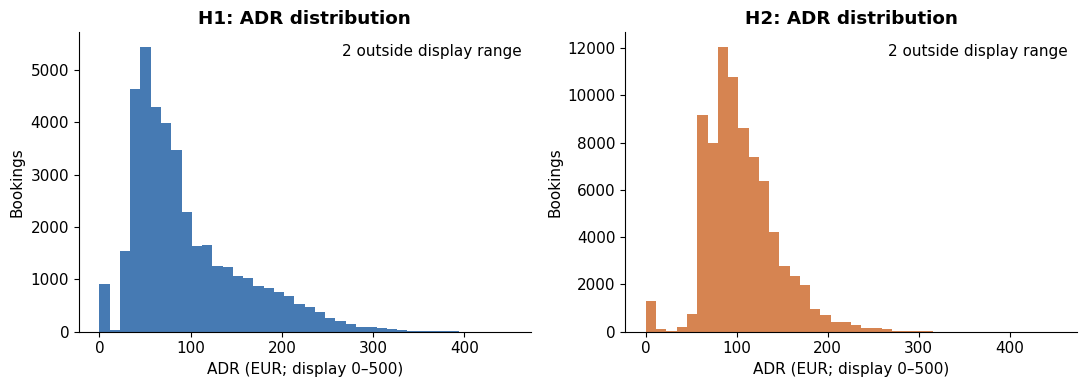

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, hotel in zip(axes, ['H1','H2']):
    d = df[df.Hotel.eq(hotel)]
    # Restrict the display only; raw values remain unchanged.
    ax.hist(d.loc[d.ADR.between(0,500), 'ADR'], bins=40, color=COLORS[hotel], alpha=.85)
    outside = int((~d.ADR.between(0,500)).sum())
    ax.set(title=f'{hotel}: ADR distribution', xlabel='ADR (EUR; display 0–500)', ylabel='Bookings')
    ax.text(.98,.96,f'{outside:,} outside display range', transform=ax.transAxes, ha='right', va='top')
show_figure('01_adr_distribution')

Zero ADR can represent a legitimate zero-priced stay; a zero-night record may represent day use, but this file alone does not establish that for each row. Negative and extreme values need separate treatments. The 1,000 EUR review threshold is an EDA flag, not a learned or approved clipping threshold.

## 3. Date and label consistency

In [6]:
canceled = df.ReservationStatus.eq('Canceled')
noshow = df.ReservationStatus.eq('No-Show')
stayed = df.ReservationStatus.eq('Check-Out')
expected_checkout = df.ArrivalDate + pd.to_timedelta(df.TotalNights, unit='D')
date_flags = pd.DataFrame({
    'Created after arrival': df.BookingCreatedDate.gt(df.ArrivalDate),
    'Canceled after arrival': canceled & df.ReservationStatusDate.gt(df.ArrivalDate),
    'Canceled before created': canceled & df.ReservationStatusDate.lt(df.BookingCreatedDate),
    'No-show date differs from arrival': noshow & df.ReservationStatusDate.ne(df.ArrivalDate),
    'Checkout date differs from arrival plus nights': stayed & df.ReservationStatusDate.ne(expected_checkout),
    'Checkout on/before scoring cutoff': stayed & df.ReservationStatusDate.le(df.CutoffDate),
}, index=df.index)
df['DateReview'] = date_flags.any(axis=1)
date_counts = date_flags.assign(Hotel=df.Hotel).groupby('Hotel').sum().T.reset_index(names='Check')
display(save_table(date_counts, 'date_checks'))
date_details = df.loc[df.DateReview, ['Hotel','Booking_ID','BookingCreatedDate','ArrivalDate','ReservationStatus','ReservationStatusDate','TotalNights']].join(date_flags.loc[df.DateReview])
save_table(date_details, 'date_review_rows')
expected_label = df.ReservationStatus.isin(['Canceled','No-Show']).astype(int)
assert df.IsCanceled.isin([0,1]).all()
assert expected_label.eq(df.IsCanceled).all()
display(pd.crosstab(df.ReservationStatus, [df.Hotel,df.IsCanceled]))
print('Distinct records needing date review:', int(df.DateReview.sum()))

Hotel,Check,H1,H2
0,Created after arrival,0,0
1,Canceled after arrival,0,0
2,Canceled before created,0,0
3,No-show date differs from arrival,1,0
4,Checkout date differs from arrival plus nights,21,6
5,Checkout on/before scoring cutoff,0,0


Hotel                 H1            H2       
IsCanceled             0      1      0      1
ReservationStatus                            
Canceled               0  10831      0  32186
Check-Out          28938      0  46228      0
No-Show                0    291      0    916

Distinct records needing date review: 28


The label agrees with final status. A date mismatch is a review flag, not proof of a data error: check-out changes or later status entry can explain some differences. Do not rewrite dates simply to force consistency; assess the affected T−14 sample separately.

## 4. T−14 sample and reconciliation with Helen

In [7]:
def eligible_at(d, horizon):
    cutoff = d.ArrivalDate - pd.Timedelta(days=horizon)
    already_resolved = d.ReservationStatus.isin(['Canceled','No-Show']) & d.ReservationStatusDate.le(cutoff)
    return d.LeadTime.ge(horizon) & ~already_resolved

df['EligibleT14'] = eligible_at(df, X)
t14 = df.loc[df.EligibleT14].copy()
flow = []
for hotel, d in df.groupby('Hotel', sort=False):
    created = d.LeadTime.ge(X)
    remaining = d.EligibleT14
    flow.append({'Hotel': hotel, 'Raw bookings': len(d), 'Created too late': int((~created).sum()),
        'Already canceled/no-show among created': int((created & ~remaining).sum()),
        'T14 bookings': int(remaining.sum()), 'Retained %': round(100 * remaining.mean(),2),
        'Label 1': int(d.loc[remaining,'IsCanceled'].sum()),
        'Label 0': int(d.loc[remaining,'IsCanceled'].eq(0).sum()),
        'Positive %': round(100 * d.loc[remaining,'IsCanceled'].mean(),2)})
flow = save_table(pd.DataFrame(flow), 't14_filter_flow')
display(flow)
for r in flow.to_dict('records'):
    assert r['Raw bookings'] == r['Created too late'] + r['Already canceled/no-show among created'] + r['T14 bookings']
    assert r['T14 bookings'] == r['Label 1'] + r['Label 0']
assert len(t14) == 58657
expected_helen = {'H1': (20305,1522), 'H2': (38352,4543)}
for hotel, d in t14.groupby('Hotel'):
    assert (len(d), int(d.IsCanceled.sum())) == expected_helen[hotel]
print('Exact match with Helen: H1 20,305 / 1,522 positives; H2 38,352 / 4,543 positives.')
display(save_table(t14.groupby(['Hotel','ReservationStatus']).size().reset_index(name='Bookings'), 't14_outcomes'))

,Hotel,Raw bookings,Created too late,Already canceled/no-show among created,T14 bookings,Retained %,Label 1,Label 0,Positive %
0,H1,40060,11095,8660,20305,50.69,1522,18783,7.50
1,H2,79330,14712,26266,38352,48.34,4543,33809,11.85


Exact match with Helen: H1 20,305 / 1,522 positives; H2 38,352 / 4,543 positives.


,Hotel,ReservationStatus,Bookings
0,H1,Canceled,1366
1,H1,Check-Out,18783
2,H1,No-Show,156
3,H2,Canceled,3936
4,H2,Check-Out,33809
5,H2,No-Show,607


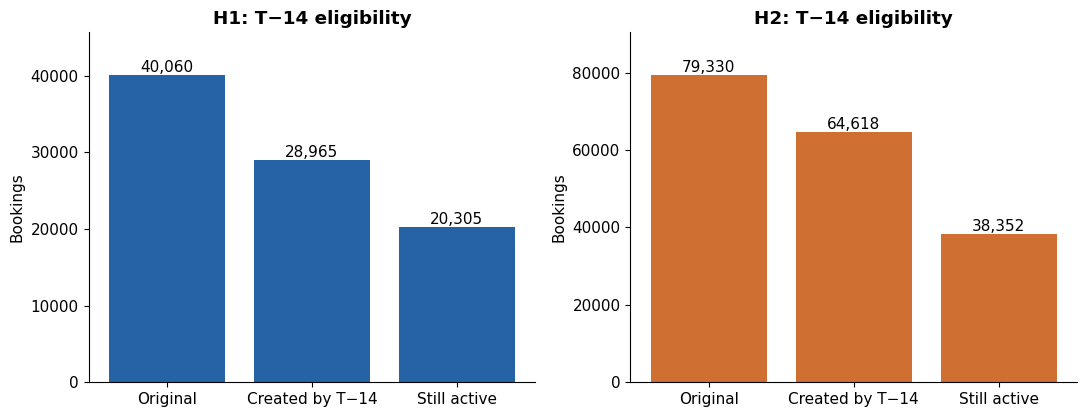

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11,4.3))
for ax, hotel in zip(axes, ['H1','H2']):
    r = flow.set_index('Hotel').loc[hotel]
    counts = [r['Raw bookings'], r['Raw bookings'] - r['Created too late'], r['T14 bookings']]
    ax.bar(['Original','Created by T−14','Still active'], counts, color=COLORS[hotel])
    for i, n in enumerate(counts): ax.text(i,n,f'{int(n):,}',ha='center',va='bottom')
    ax.set(title=f'{hotel}: T−14 eligibility',ylabel='Bookings',ylim=(0,max(counts)*1.14))
show_figure('02_t14_sample_flow')

,X,Hotel,Bookings,Positives,Positive %,Retained %,No-show share of positives %
0,3,H1,24111,612,2.54,60.19,35.13
1,3,H2,42385,1628,3.84,53.43,46.13
2,7,H1,22028,927,4.21,54.99,20.82
3,7,H2,40465,3085,7.62,51.01,21.94
4,14,H1,20305,1522,7.50,50.69,10.25
5,14,H2,38352,4543,11.85,48.34,13.36
6,21,H1,19281,1954,10.13,48.13,7.16
7,21,H2,36501,5603,15.35,46.01,9.69
8,30,H1,17943,2199,12.26,44.79,5.55
9,30,H2,34646,6329,18.27,43.67,7.66


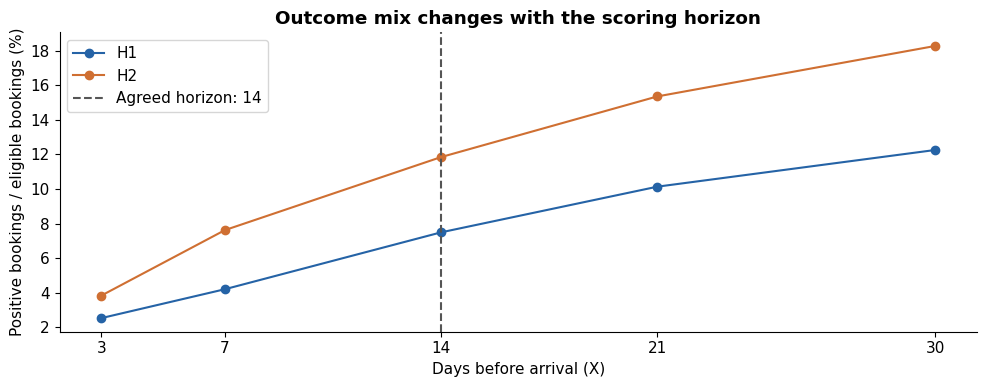

In [9]:
horizons=[]
for horizon in [3,7,14,21,30]:
    for hotel, d in df.groupby('Hotel'):
        s=d.loc[eligible_at(d,horizon)]
        positives=int(s.IsCanceled.sum())
        horizons.append({'X':horizon,'Hotel':hotel,'Bookings':len(s),'Positives':positives,
            'Positive %':100*s.IsCanceled.mean(), 'Retained %':100*len(s)/len(d),
            'No-show share of positives %':100*s.ReservationStatus.eq('No-Show').sum()/positives})
horizons=save_table(pd.DataFrame(horizons), 'horizon_comparison')
display(horizons.round(2))
fig,ax=plt.subplots(figsize=(10,4))
for hotel,d in horizons.groupby('Hotel'):
    ax.plot(d.X,d['Positive %'],marker='o',color=COLORS[hotel],label=hotel)
ax.axvline(14,color='#555',linestyle='--',label='Agreed horizon: 14')
ax.set(xlabel='Days before arrival (X)',ylabel='Positive bookings / eligible bookings (%)',title='Outcome mix changes with the scoring horizon',xticks=[3,7,14,21,30])
ax.legend()
show_figure('03_horizon_positive_rates')

T−14 reproduces the agreed sample. A larger X changes which bookings are eligible and the outcome mix; this comparison does not establish model accuracy or an industry-standard optimal horizon. Keep both outcomes when training, not only cancellations.

## 5. Cleaning sensitivity — separate evidence from decisions
These are illustrative exclusions applied independently to the raw T−14 sample. They are not a production cleaning pipeline.

In [10]:
sens=[]
for hotel,d in t14.groupby('Hotel'):
    rules={'Unchanged T14':pd.Series(True,index=d.index),
           'Exclude known zero guests':~d.PartySize.eq(0),
           'Exclude zero nights (overnight scope)':~d.TotalNights.eq(0),
           'Exclude date-review rows':~d.DateReview,
           'Exclude zero guests OR zero nights':~(d.PartySize.eq(0)|d.TotalNights.eq(0)),
           'Exclude H2 soft-opening period':~(d.Hotel.eq('H2') & d.ArrivalDate.lt('2015-09-01'))}
    for rule,mask in rules.items():
        s=d.loc[mask]
        sens.append({'Hotel':hotel,'Scenario':rule,'Removed':len(d)-len(s),'Remaining':len(s),
                     'Positives':int(s.IsCanceled.sum()),'Positive %':100*s.IsCanceled.mean()})
sensitivity=save_table(pd.DataFrame(sens), 'cleaning_sensitivity')
display(sensitivity.round(2))
display(t14.groupby('Hotel').agg(Negative_ADR=('ADR',lambda s:int(s.lt(0).sum())),
    Extreme_ADR_over_1000=('ADR',lambda s:int(s.gt(1000).sum())), Missing_children=('Children',lambda s:int(s.isna().sum()))))

,Hotel,Scenario,Removed,Remaining,Positives,Positive %
0,H1,Unchanged T14,0,20305,1522,7.50
1,H1,Exclude known zero guests,7,20298,1522,7.50
2,H1,Exclude zero nights (overnight scope),158,20147,1518,7.53
3,H1,Exclude date-review rows,19,20286,1522,7.50
4,H1,Exclude zero guests OR zero nights,165,20140,1518,7.54
5,H1,Exclude H2 soft-opening period,0,20305,1522,7.50
6,H2,Unchanged T14,0,38352,4543,11.85
7,H2,Exclude known zero guests,53,38299,4540,11.85
8,H2,Exclude zero nights (overnight scope),69,38283,4538,11.85
9,H2,Exclude date-review rows,5,38347,4543,11.85


,Negative_ADR,Extreme_ADR_over_1000,Missing_children
Hotel,,,
H1,1,0,0
H2,0,0,0


H2's July–August 2015 period is described as a soft opening in the original authors' deployment study. Treat it as an operating-regime difference; the sensitivity above quantifies removal without silently deleting it from the primary analysis.

## 6. EstimatedRoomCount — H1 / 2 and H2 / 4
Main scenario: total people = `Adults + Children + Babies`. Missing totals and zero-person bookings receive no estimate. Adults-only estimates are a sensitivity, not a change to the agreed capacities. Neither scenario is observed room count, hotel capacity, or confirmed room availability.

,Population,Hotel,Bookings,People per room,Unknown estimate,Mean estimated rooms,2+ rooms % of known,Maximum rooms,Different from adults-only
0,All bookings,H1,40060,2,13,1.128,12.281,28,3461
1,All bookings,H2,79330,4,171,1.001,0.119,3,94
2,T14,H1,20305,2,7,1.134,13.238,6,1821
3,T14,H2,38352,4,53,1.001,0.131,3,50


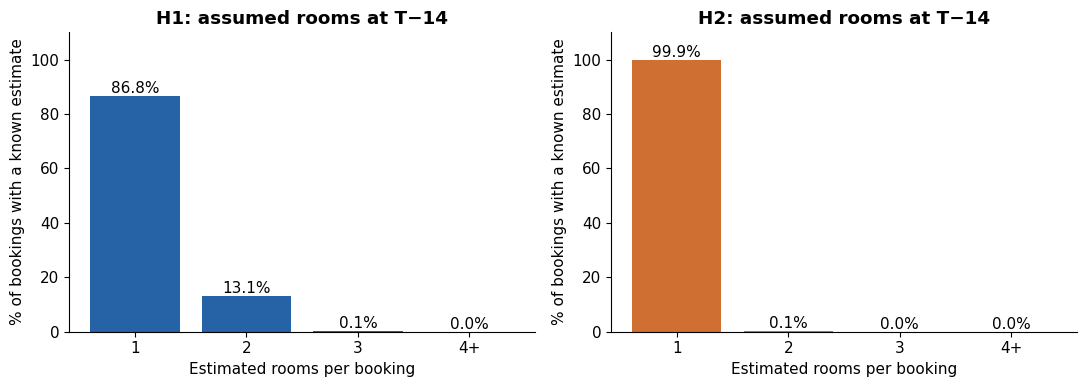

In [11]:
capacity = df.Hotel.map(PEOPLE_PER_ROOM)
df['EstimatedRoomCount'] = np.ceil(df.PartySize / capacity).where(df.PartySize.gt(0)).astype('Int64')
df['RoomsAdultsOnlySensitivity'] = np.ceil(df.Adults / capacity).where(df.Adults.gt(0)).astype('Int64')
room_summary=[]
for population,mask in [('All bookings',pd.Series(True,index=df.index)),('T14',df.EligibleT14)]:
    for hotel,d in df.loc[mask].groupby('Hotel'):
        valid=d.EstimatedRoomCount.notna()
        comparable=valid & d.RoomsAdultsOnlySensitivity.notna()
        room_summary.append({'Population':population,'Hotel':hotel,'Bookings':len(d),
            'People per room':PEOPLE_PER_ROOM[hotel], 'Unknown estimate':int((~valid).sum()),
            'Mean estimated rooms':float(d.EstimatedRoomCount.mean()),
            '2+ rooms % of known':100*float(d.loc[valid,'EstimatedRoomCount'].ge(2).mean()),
            'Maximum rooms':int(d.EstimatedRoomCount.max()),
            'Different from adults-only':int((d.loc[comparable,'EstimatedRoomCount'] != d.loc[comparable,'RoomsAdultsOnlySensitivity']).sum())})
room_summary=save_table(pd.DataFrame(room_summary), 'room_assumption_summary')
display(room_summary.round(3))
save_table(df[['Hotel','Booking_ID','Adults','Children','Babies','PartySize','EstimatedRoomCount','RoomsAdultsOnlySensitivity','EligibleT14']], 'room_assumption_audit')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,hotel in zip(axes,['H1','H2']):
    d=df.loc[df.Hotel.eq(hotel)&df.EligibleT14,'EstimatedRoomCount'].dropna()
    counts=d.clip(upper=4).value_counts().reindex([1,2,3,4],fill_value=0)
    shares=100*counts/len(d)
    ax.bar(['1','2','3','4+'],shares,color=COLORS[hotel])
    for i,v in enumerate(shares):ax.text(i,v,f'{v:.1f}%',ha='center',va='bottom')
    ax.set(title=f'{hotel}: assumed rooms at T−14',xlabel='Estimated rooms per booking',ylabel='% of bookings with a known estimate',ylim=(0,110))
show_figure('04_estimated_rooms')

Room type codes cannot recover the number of rooms. Adding `EstimatedRoomCount` summarizes existing guest counts under a capacity assumption; it does not introduce new observed information. Keep it separate for business reporting, and do not automatically include it as a model predictor.

## 7. Feature patterns and exclusion rules

,Feature,Hotel,Value,Bookings,Positive bookings,Positive %
0,DepositType,H1,No Deposit,20095,1462,7.28
1,DepositType,H1,Non Refund,98,42,42.86
2,DepositType,H1,Refundable,112,18,16.07
3,DepositType,H2,No Deposit,38019,4232,11.13
4,DepositType,H2,Non Refund,319,302,94.67
5,DepositType,H2,Refundable,14,9,64.29


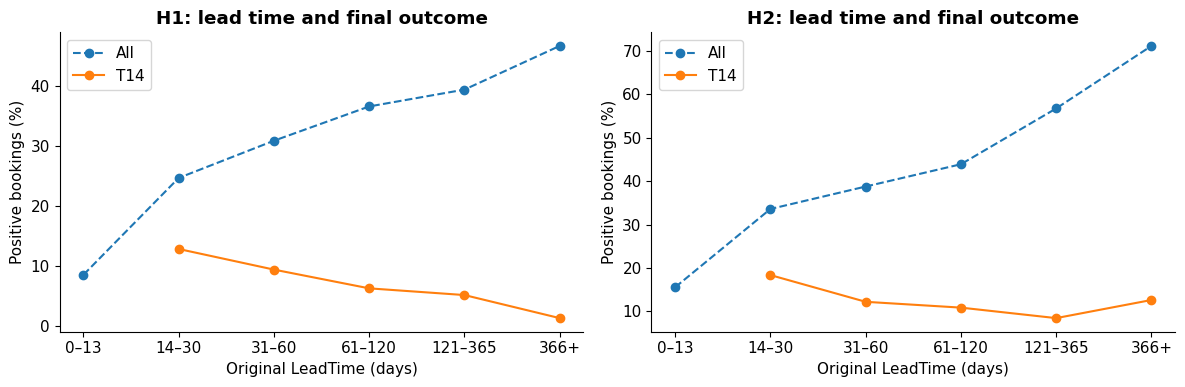

In [12]:
feature_rows=[]
for feature in ['DepositType','MarketSegment','CustomerType','DistributionChannel','ReservedRoomType']:
    for (hotel,value),d in t14.groupby(['Hotel',feature]):
        feature_rows.append({'Feature':feature,'Hotel':hotel,'Value':value,'Bookings':len(d),
            'Positive bookings':int(d.IsCanceled.sum()),'Positive %':100*d.IsCanceled.mean()})
feature_rates=save_table(pd.DataFrame(feature_rows), 'categorical_outcome_rates_t14')
display(feature_rates[feature_rates.Feature.eq('DepositType')].round(2))
bins=[-1,13,30,60,120,365,np.inf]
labels=['0–13','14–30','31–60','61–120','121–365','366+']
df['LeadTimeBand']=pd.cut(df.LeadTime,bins=bins,labels=labels)
lead_tables=[]
for population,d in [('All',df),('T14',df[df.EligibleT14])]:
    t=d.groupby(['Hotel','LeadTimeBand'],observed=True).agg(Bookings=('IsCanceled','size'),Positive_rate=('IsCanceled','mean')).reset_index()
    t['Population']=population;lead_tables.append(t)
lead_rates=save_table(pd.concat(lead_tables,ignore_index=True), 'leadtime_outcomes')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,hotel in zip(axes,['H1','H2']):
    for pop,style in [('All','--'),('T14','-')]:
        t=lead_rates[(lead_rates.Hotel==hotel)&(lead_rates.Population==pop)]
        ax.plot(t.LeadTimeBand.astype(str),100*t.Positive_rate,marker='o',linestyle=style,label=pop)
    ax.set(title=f'{hotel}: lead time and final outcome',xlabel='Original LeadTime (days)',ylabel='Positive bookings (%)')
    ax.legend()
show_figure('05_leadtime_selection_effect')

The T−14 population is selected after early cancellations have been removed. Associations can differ from the full dataset. A rare category can still have a high cancellation rate; inspect both support and rate. These are descriptive associations, not evidence that a feature causes cancellation or improves a model.

In [13]:
feature_policy = pd.DataFrame([
    ['IsCanceled','Label only','Existing final outcome; never a predictor.'],
    ['ReservationStatus; ReservationStatusDate','Exclude from predictors','Use only for eligibility, label checks and outcome maturity.'],
    ['Booking_ID; Hotel; ArrivalDate; CutoffDate; BookingCreatedDate','Metadata / routing','Traceability and time operations. Hotel routes separate outputs. Date components may be predictors.'],
    ['Country','Recommend exclude','Authors report default Portugal values corrected at check-in: documented leakage risk.'],
    ['AssignedRoomType; RequiredCarParkingSpaces','Exclude in agreed baseline','Meeting decision. Strong association alone does not establish leakage for every row.'],
    ['Agent; Company','Exclude in proposed baseline','Identifier-like codes; not free-text. Exclusion is a scope choice, not proof of leakage.'],
    ['BookingChanges; DaysInWaitingList; TotalOfSpecialRequests; ADR','Candidate under fixed-details assumption','Keep timing assumption explicit. ADR also needs its observed quality rules.'],
    ['LeadTime; ArrivalDateYear; ArrivalDateMonth; ArrivalDateWeekNumber; ArrivalDateDayOfMonth','Candidate','Do not discard calendar columns merely because some are related.'],
    ['Adults; Children; Babies; StaysInWeekNights; StaysInWeekendNights','Candidate','Preserve missing Children until a training-only imputation rule is fitted.'],
    ['Meal; MarketSegment; DistributionChannel; ReservedRoomType; DepositType; CustomerType','Candidate categorical','One-hot encoding fitted on training data; handle unseen categories.'],
    ['IsRepeatedGuest; PreviousCancellations; PreviousBookingsNotCanceled','Candidate','Booking history counts, under the agreed availability assumption.'],
    ['ArrivalDayOfWeek; TotalNights; PartySize','Derived candidate','Weekday from the date; sums preserve missing required inputs.'],
    ['EstimatedRoomCount','Scenario / reporting','Assumed capacities H1=2, H2=4; not actual room count.'],
],columns=['Columns','Proposed role','Reason / treatment'])
display(save_table(feature_policy,'feature_policy'))

,Columns,Proposed role,Reason / treatment
0,IsCanceled,Label only,Existing final outcome; never a predictor.
1,ReservationStatus; ReservationStatusDate,Exclude from predictors,"Use only for eligibility, label checks and out..."
2,Booking_ID; Hotel; ArrivalDate; CutoffDate; Bo...,Metadata / routing,Traceability and time operations. Hotel routes...
3,Country,Recommend exclude,Authors report default Portugal values correct...
4,AssignedRoomType; RequiredCarParkingSpaces,Exclude in agreed baseline,Meeting decision. Strong association alone doe...
5,Agent; Company,Exclude in proposed baseline,Identifier-like codes; not free-text. Exclusio...
6,BookingChanges; DaysInWaitingList; TotalOfSpec...,Candidate under fixed-details assumption,Keep timing assumption explicit. ADR also need...
7,LeadTime; ArrivalDateYear; ArrivalDateMonth; A...,Candidate,Do not discard calendar columns merely because...
8,Adults; Children; Babies; StaysInWeekNights; S...,Candidate,Preserve missing Children until a training-onl...
9,Meal; MarketSegment; DistributionChannel; Rese...,Candidate categorical,One-hot encoding fitted on training data; hand...


## 8. Time splits and outcome availability
The table uses the proposal's arrival-date windows for review: train through December 2016, validation January–April 2017, test May–August 2017. In a deployment simulation, a training label must also have become known before the next scoring period begins.

,Hotel,Split,Bookings,Positives,Positive %
0,H1,Test,3610,249,6.90
1,H1,Train,13924,1051,7.55
2,H1,Validation,2771,222,8.01
3,H2,Test,7830,618,7.89
4,H2,Train,24844,3329,13.40
5,H2,Validation,5678,596,10.50


,Hotel,Next period,First scoring day,Candidate training rows,Known before first scoring day,Not yet known
0,H1,Validation,2016-12-18,13924,13511,413
1,H1,Test,2017-04-17,16695,16136,559
2,H2,Validation,2016-12-18,24844,24261,583
3,H2,Test,2017-04-17,30522,29502,1020


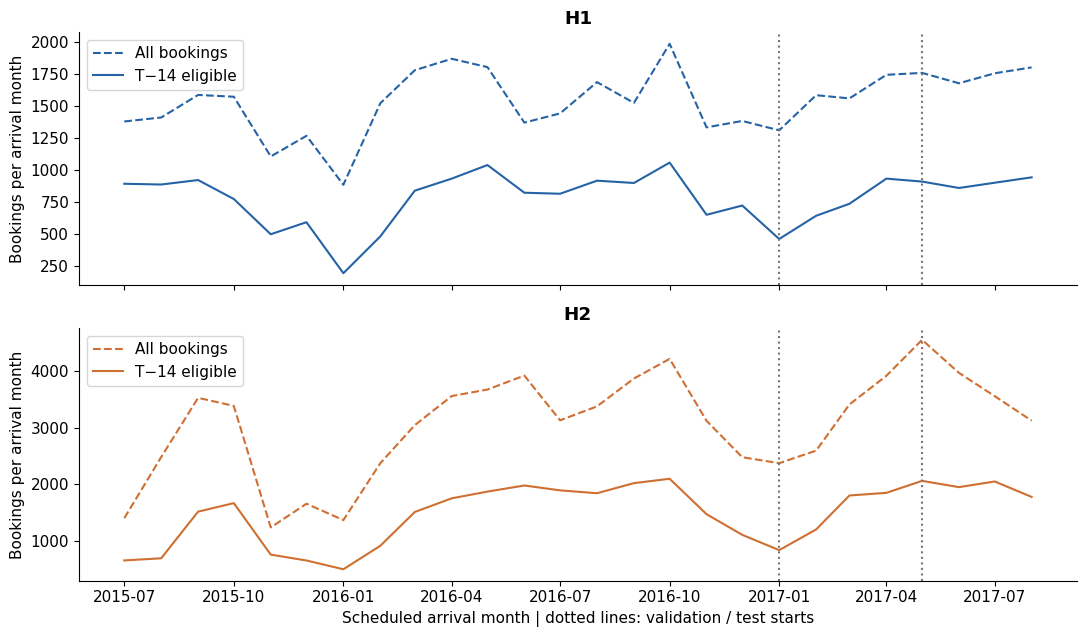

In [14]:
t14['Split']=np.select([t14.ArrivalDate.lt('2017-01-01'),t14.ArrivalDate.lt('2017-05-01')],['Train','Validation'],default='Test')
split_summary=t14.groupby(['Hotel','Split']).agg(Bookings=('IsCanceled','size'),Positives=('IsCanceled','sum'),Positive_rate=('IsCanceled','mean')).reset_index()
split_summary['Positive %']=100*split_summary.pop('Positive_rate')
display(save_table(split_summary,'temporal_split_summary').round(2))
maturity=[]
for hotel,d in t14.groupby('Hotel'):
    for target,prior in [('Validation',['Train']),('Test',['Train','Validation'])]:
        first_score=d.loc[d.Split.eq(target),'CutoffDate'].min()
        pool=d[d.Split.isin(prior)]
        ready=pool.ReservationStatusDate.lt(first_score)
        maturity.append({'Hotel':hotel,'Next period':target,'First scoring day':first_score.date(),
            'Candidate training rows':len(pool),'Known before first scoring day':int(ready.sum()),
            'Not yet known':int((~ready).sum())})
display(save_table(pd.DataFrame(maturity),'label_maturity'))
monthly=df.groupby(['Hotel',pd.Grouper(key='ArrivalDate',freq='MS')]).agg(Bookings=('IsCanceled','size')).reset_index()
eligible_monthly=t14.groupby(['Hotel',pd.Grouper(key='ArrivalDate',freq='MS')]).size().reset_index(name='EligibleT14')
monthly=monthly.merge(eligible_monthly,on=['Hotel','ArrivalDate'],how='left',validate='one_to_one')
save_table(monthly,'monthly_booking_volume')
fig,axes=plt.subplots(2,1,figsize=(11,6.5),sharex=True)
for ax,hotel in zip(axes,['H1','H2']):
    d=monthly[monthly.Hotel.eq(hotel)]
    ax.plot(d.ArrivalDate,d.Bookings,label='All bookings',color=COLORS[hotel],linestyle='--')
    ax.plot(d.ArrivalDate,d.EligibleT14,label='T−14 eligible',color=COLORS[hotel])
    for boundary in ['2017-01-01','2017-05-01']:ax.axvline(pd.Timestamp(boundary),color='#777',linestyle=':')
    ax.set(title=hotel,ylabel='Bookings per arrival month');ax.legend(loc='upper left')
axes[-1].set_xlabel('Scheduled arrival month | dotted lines: validation / test starts')
show_figure('06_monthly_booking_volume')

## 9. Additional sources — raw downloads and coverage

In [15]:
manifest_path=ROOT/'data/external/source_manifest.json'
manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
source_table=pd.DataFrame([{'File':r['file'],'Status':r['status'],'Bytes':r.get('bytes',0)} for r in manifest])
display(save_table(source_table,'external_source_status'))
for record in manifest:
    if 'sha256' in record:
        assert hashlib.sha256((ROOT/'data/external'/record['file']).read_bytes()).hexdigest()==record['sha256']
print('All available external source checksums verified.')

,File,Status,Bytes
0,holidays/holidays_PT_2015.json,downloaded,3084
1,holidays/holidays_PT_2016.json,downloaded,3084
2,holidays/holidays_PT_2017.json,downloaded,3084
3,exchange_rates/ecb_eurusd_2014_2017.csv,downloaded,194607
4,holidays/law_23_2012.html,downloaded,2346
5,holidays/law_8_2016.html,downloaded,2346
6,google_trends/google_trends_hotels_flights_wee...,user_downloaded,0


All available external source checksums verified.


### 9.1 Portugal national holidays
The API includes four dates that were suspended in 2015. Correct those against legislation. Exclude optional Carnival and regional holidays; use only national mandatory holidays. The four restored holidays became effective on 2 April 2016.

In [16]:
restored={'Corpus Christi','Republic Day','All Saints Day','Restoration of Independence'}
standard={"New Year's Day",'Good Friday','Easter Sunday','Freedom Day','Labour Day','National Day','Assumption Day','Immaculate Conception','Christmas Day'}
holiday_rows=[];holiday_audit=[]
for year in [2015,2016,2017]:
    data=json.loads((ROOT/f'data/external/holidays/holidays_PT_{year}.json').read_text(encoding='utf-8'))
    for row in data:
        allowed=standard | (restored if year>=2016 else set())
        keep=row['global'] and row['name'] in allowed
        holiday_audit.append({'Date':row['date'],'Name':row['name'],'Include':keep,
            'Reason':'National mandatory holiday' if keep else ('Suspended in 2015' if year==2015 and row['name'] in restored else 'Regional / optional / outside scope')})
        if keep:
            holiday_rows.append({'ArrivalDate':pd.Timestamp(row['date']),'HolidayName':row['name'],
                'HolidayKnownFrom':pd.Timestamp('2016-04-02' if row['name'] in restored else '2012-06-25')})
holidays=pd.DataFrame(holiday_rows)
assert holidays.ArrivalDate.is_unique
counts=holidays.groupby(holidays.ArrivalDate.dt.year).size()
assert counts.to_dict()=={2015:9,2016:13,2017:13}
display(counts.rename('National holiday dates').to_frame())
save_table(pd.DataFrame(holiday_audit),'holiday_corrections')
save_table(holidays,'reviewed_holidays')
calendar_df=pd.DataFrame({'ArrivalDate':pd.date_range('2015-01-01','2017-12-31')}).merge(holidays,on='ArrivalDate',how='left',validate='one_to_one')
enriched=t14.merge(calendar_df,on='ArrivalDate',how='left',validate='many_to_one')
enriched['IsPortugalHoliday']=enriched.HolidayName.notna() & enriched.HolidayKnownFrom.le(enriched.CutoffDate)
assert len(enriched)==len(t14)
assert enriched.Booking_ID.is_unique
holiday_check=enriched.groupby('Hotel').agg(Bookings=('Booking_ID','size'),Holiday_arrivals=('IsPortugalHoliday','sum'))
holiday_check['Holiday arrival %']=100*holiday_check.Holiday_arrivals/holiday_check.Bookings
display(save_table(holiday_check.reset_index(),'holiday_join_check').round(2))

,National holiday dates
ArrivalDate,
2015,9
2016,13
2017,13


,Hotel,Bookings,Holiday_arrivals,Holiday arrival %
0,H1,20305,647,3.19
1,H2,38352,1325,3.45


### 9.2 EUR/USD
Unit: **USD per EUR**. Lower values mean a weaker euro relative to the dollar. For scoring, use the most recent observation strictly before the cutoff date, avoiding same-day release-time ambiguity and forward-filling only from the past. This is market context, not a claim about each guest's payment currency.

,Hotel,Bookings,Missing_FX,Max_age_days
0,H1,20305,0,5
1,H2,38352,0,5


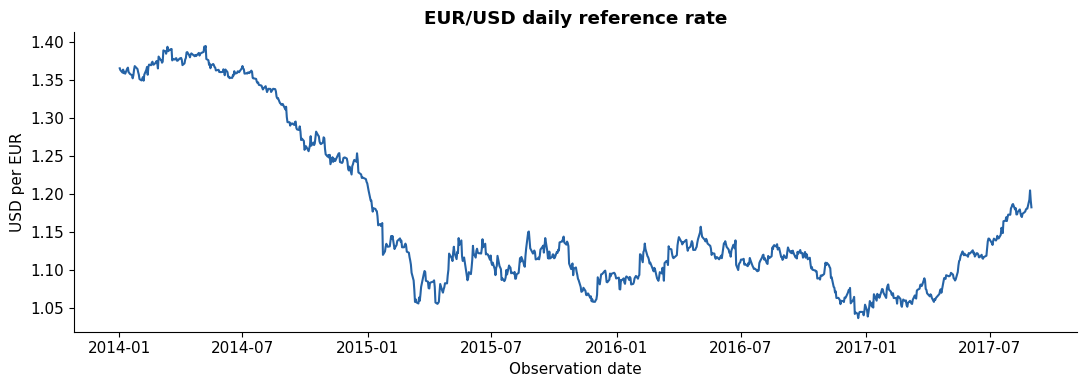

In [17]:
fx_dir=ROOT/'data/external/exchange_rates'
fx_path=fx_dir/'ecb_eurusd_2014_2017.csv'
fx=pd.read_csv(fx_path)
fx=fx.loc[fx.CURRENCY.eq('USD') & fx.CURRENCY_DENOM.eq('EUR'),['TIME_PERIOD','OBS_VALUE']].rename(columns={'TIME_PERIOD':'FXObservationDate','OBS_VALUE':'EURUSD'})
fx['FXObservationDate']=pd.to_datetime(fx.FXObservationDate)
fx=fx.sort_values('FXObservationDate')
assert fx.FXObservationDate.is_unique and fx.EURUSD.gt(0).all()
enriched=pd.merge_asof(enriched.sort_values('CutoffDate'),fx,left_on='CutoffDate',right_on='FXObservationDate',direction='backward',allow_exact_matches=False)
assert len(enriched)==len(t14) and enriched.Booking_ID.is_unique
assert enriched.EURUSD.notna().all()
assert (enriched.FXObservationDate<enriched.CutoffDate).all()
enriched['FXAgeDays']=(enriched.CutoffDate-enriched.FXObservationDate).dt.days
display(save_table(enriched.groupby('Hotel').agg(Bookings=('Booking_ID','size'),Missing_FX=('EURUSD',lambda s:int(s.isna().sum())),Max_age_days=('FXAgeDays','max')).reset_index(),'fx_join_check'))
save_table(fx,'reviewed_eurusd')
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(fx.FXObservationDate,fx.EURUSD,color='#2563A6')
ax.set(title='EUR/USD daily reference rate',xlabel='Observation date',ylabel='USD per EUR')
show_figure('07_eurusd')

### 9.3 Join checks
Holidays and FX are matched below. The current Google Trends source and join rules are described in the project `README.ipynb`.

In [18]:
join_status=pd.DataFrame([
    ['Portugal public holidays',len(t14),len(enriched),0,'Reviewed historical national calendar'],
    ['EUR/USD',len(t14),len(enriched),int(enriched.EURUSD.isna().sum()),'Prior observation date; daily publication convention'],
],columns=['Source','Input bookings','Joined bookings','Missing','Readiness'])
display(save_table(join_status,'external_join_readiness'))

,Source,Input bookings,Joined bookings,Missing,Readiness
0,Portugal public holidays,58657,58657,0,Reviewed historical national calendar
1,EUR/USD,58657,58657,0,Prior observation date; daily publication conv...


## 10. Proposed treatments and handoff
Only observed issues are listed below. These proposals are not silently applied to raw data. Decisions on business scope and unusual records remain explicit.

In [19]:
treatments=pd.DataFrame([
    ['Source whitespace','Observed in categorical fields','Trim strings; keep source files unchanged.','Ready'],
    ['Identical-looking rows','Both hotels have duplicate groups','Retain rows; assign stable source-row Booking_ID.','Agreed'],
    ['Agent / Company NULL','No agent/company recorded','Preserve meaning as none in Silver; proposed exclusion from predictors.','Scope choice'],
    ['Missing Children','Observed in H2','Keep missing PartySize/room estimates; fit any imputation on train only.','Ready'],
    ['Negative ADR','Observed in H1','Set to missing in cleaned data; preserve original for audit.','Proposed'],
    ['Extreme ADR','H2 contains ADR = 5400','Flag for review. Do not derive a full-dataset clipping threshold.','Decision needed'],
    ['Zero ADR','Observed in both hotels','Retain unless business scope explicitly excludes complimentary stays.','Proposed'],
    ['Zero guests','Observed in both hotels','Quarantine from guest/room-based sample; retain raw records.','Proposed'],
    ['Zero nights','Observed in both hotels','If overnight-stay scope, exclude; do not assume all are proven day-use bookings.','Scope decision'],
    ['Date inconsistencies','Exported individual records','Review/quarantine unresolved cases; do not rewrite dates to fit expectations.','Proposed'],
    ['Country','Documented late correction in authors study','Exclude from baseline predictors and country-derived joins.','Recommended'],
    ['H2 early period','Authors describe soft opening through Aug 2015','Compare retaining vs excluding this period from training.','Scope decision'],
],columns=['Issue','Evidence','Proposed treatment','Status'])
display(save_table(treatments,'proposed_treatments'))

,Issue,Evidence,Proposed treatment,Status
0,Source whitespace,Observed in categorical fields,Trim strings; keep source files unchanged.,Ready
1,Identical-looking rows,Both hotels have duplicate groups,Retain rows; assign stable source-row Booking_ID.,Agreed
2,Agent / Company NULL,No agent/company recorded,Preserve meaning as none in Silver; proposed e...,Scope choice
3,Missing Children,Observed in H2,Keep missing PartySize/room estimates; fit any...,Ready
4,Negative ADR,Observed in H1,Set to missing in cleaned data; preserve origi...,Proposed
5,Extreme ADR,H2 contains ADR = 5400,Flag for review. Do not derive a full-dataset ...,Decision needed
6,Zero ADR,Observed in both hotels,Retain unless business scope explicitly exclud...,Proposed
7,Zero guests,Observed in both hotels,Quarantine from guest/room-based sample; retai...,Proposed
8,Zero nights,Observed in both hotels,"If overnight-stay scope, exclude; do not assum...",Scope decision
9,Date inconsistencies,Exported individual records,Review/quarantine unresolved cases; do not rew...,Proposed


## Final measured summary

In [20]:
summary_lines=[]
for hotel,d in t14.groupby('Hotel'):
    summary_lines.append(f"- **{hotel}:** {len(d):,} T−14 bookings; {int(d.IsCanceled.sum()):,} positive outcomes ({100*d.IsCanceled.mean():.2f}%).")
summary_lines += [
    f"- **Date review:** {int(df.DateReview.sum()):,} source rows; {int(t14.DateReview.sum()):,} remain in the uncleaned T−14 sample.",
    f"- **Source quality:** {int(df.PartySize.eq(0).sum()):,} zero-guest records; {int(df.TotalNights.eq(0).sum()):,} zero-night records. These groups can overlap.",
    '- **Helen reconciliation:** T−14 counts and positives match. Alex uses the later agreed H1/H2 capacities of 2/4; Helen used adults/2 for both hotels.',
    '- **External joins:** reviewed holidays and prior-day EUR/USD preserve booking counts. Google Trends is an offline experiment verified by the formal pipeline checks.',
    '- **No model training or Gold generation:** EDA tables and estimates are review outputs only.'
]
display(Markdown('\n'.join(summary_lines)))
validation={'runtime':versions,'raw_rows':len(df),'raw_columns_per_hotel':31,'t14_rows':len(t14),
    't14_positives':int(t14.IsCanceled.sum()),'date_review_rows':int(df.DateReview.sum()),
    't14_date_review_rows':int(t14.DateReview.sum()),'holiday_counts':{str(k):int(v) for k,v in counts.items()},
    'fx_rows':len(fx),'fx_missing_at_t14':int(enriched.EURUSD.isna().sum()),
    'helen_notebook_sha256':hashlib.sha256((ROOT/'EDA/Helen_EDA_Hotel_Booking.ipynb').read_bytes()).hexdigest(),
    'original_hotel_files_unchanged':all(hashlib.sha256((ROOT/r['file']).read_bytes()).hexdigest()==r['sha256'] for r in hashes)}
(OUT/'validation_summary.json').write_text(json.dumps(validation,indent=2),encoding='utf-8')
print('Results saved to EDA/results. All assertions passed.')

- **H1:** 20,305 T−14 bookings; 1,522 positive outcomes (7.50%).
- **H2:** 38,352 T−14 bookings; 4,543 positive outcomes (11.85%).
- **Date review:** 28 source rows; 24 remain in the uncleaned T−14 sample.
- **Source quality:** 180 zero-guest records; 715 zero-night records. These groups can overlap.
- **Helen reconciliation:** T−14 counts and positives match. Alex uses the later agreed H1/H2 capacities of 2/4; Helen used adults/2 for both hotels.
- **External joins:** reviewed holidays and prior-day EUR/USD preserve booking counts. Google Trends is an offline experiment verified by the formal pipeline checks.
- **No model training or Gold generation:** EDA tables and estimates are review outputs only.

Results saved to EDA/results. All assertions passed.
